<h1> McDonalds Data Analysis Project </h1>
<p>This project was created to analyze the nutritional fact of multinational fast food chain McDonalds.This dataset provides a list of all of the McDonalds menu items the nutritional value for these items. With the data set provided I will use descriptive analysis to summarize key values of the data set.  </p>

<h1> Tools of the Trade</h1>
<p>For this project I will be using python. I have imported the following libraries Numpy for linear algebra, Pandas for data processing, matplotlib for graph plotting, and seaborn for data visualization. </p>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # matplotlib is a low level graph plotting library in python that serves as a visualization utility.
import seaborn as sns # seaborn is a statistical data visualization toll.

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session√

/kaggle/input/nutrition-facts/menu.csv


<h1> Here is the data set for this project</h1>
    <h7>Data set contains 9 catagories(See below) </h7>
	<ul>
  <li>Coffee and Tea</li>
  <li>Breakfast</li>
  <li>Smoothies and Shakes</li>
  <li>Chicken and Fish</li>
    <li>Beverages</li>
  <li>Beef and Pork</li>
    <li>Snacks and Sides</li>
  <li>Desserts</li>
    <li>Salads</li>
 </ul>
  <h7>Within those 9 catagories there are 260 different items. The first table is sample set for the data table, the data shape (number of columns and rows), and the catagory with the highest number of items.</h7>

In [2]:
data = pd.read_csv("../input/nutrition-facts/menu.csv") #show the nutrition-facts spreadsheet.
data.head(2)

,Category,Item,Serving Size,Calories,Calories from Fat,Total Fat,Total Fat (% Daily Value),Saturated Fat,Saturated Fat (% Daily Value),Trans Fat,...,Carbohydrates,Carbohydrates (% Daily Value),Dietary Fiber,Dietary Fiber (% Daily Value),Sugars,Protein,Vitamin A (% Daily Value),Vitamin C (% Daily Value),Calcium (% Daily Value),Iron (% Daily Value)
0,Breakfast,Egg McMuffin,4.8 oz (136 g),300,120,13.0,20,5.0,25,0.0,...,31,10,4,17,3,17,10,0,25,15
1,Breakfast,Egg White Delight,4.8 oz (135 g),250,70,8.0,12,3.0,15,0.0,...,30,10,4,17,3,18,6,0,25,8


In [3]:
data.shape #code outputs the dimension of the python object. Output 260 rows and 24 columns

(260, 24)

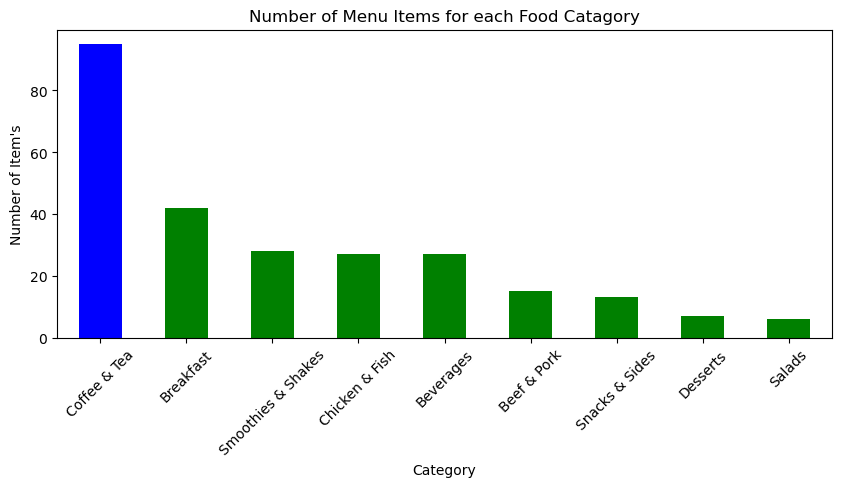

In [4]:
#Graph for Number of Menu Items for each Catagory
plt.figure(figsize=(10, 4), dpi=100) #Input plot size
menu_category = data.Category.value_counts() #import data
menu_category.plot.bar(color = ['blue','green','green','green','green','green','green','green','green']) #graph color
plt.title("Number of Menu Items for each Food Catagory") # Graphs Main Label on the Top
plt.ylabel("Number of Item's") # Y-plot Label
plt.xlabel("Category") # X-plot Label
plt.xticks(rotation=45) #angle of x-plot Label
plt.show() #display results

<H1>Let's Talk About Fats</H1>
<P>According to the Harvard School of Public Health, instead of promoting low-fat foods, it is important to recognize the significance of healthy fats for our overall health. Contrary to popular belief, there is generally no direct link between the percentage of calories obtained from fat and major health risks. Fats can be divided into three categories:</P>


<b>Unsaturated Fats:</b> These fats are beneficial for our health and carry a lower risk of diseases. Some examples include vegetable oils, fish, nuts, and seeds.

<b>Trans Fats:</b> These fats are considered unhealthy and can increase the risk of diseases, even when consumed in small quantities. The category that has the highest trans fats is beef and pork(See Trans Fat Graph and Data Below). 

<b>Saturated Fats:</b> While not as harmful as trans fats, saturated fats can still pose risks if consumed excessively. The Dietary Guidelines for Americans recommend that saturated fat intake should not exceed 10% of daily calorie intake, and the American Heart Association suggests aiming for a dietary pattern that consists of 5% to 6% of calories from saturated fats. The category that has the highest saturated fat is beverages (See Saturated Fat Graph and Data Below). 




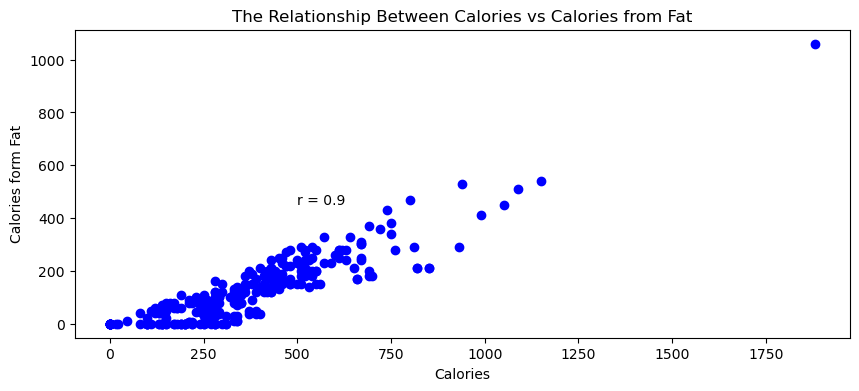

In [5]:
#Plot graph for relationship between Calories vs Calories from Fat
plt.figure(figsize=(10, 4), dpi=100) #Input plot size

correlation = data['Calories'].corr(data['Calories from Fat']) #Graph Size
plt.scatter(data.Calories, data['Calories from Fat'], color='blue') #Get scatterplot, data, and plot color
plt.text(500,450, 'r = {}'.format(round(correlation,2)))
plt.xlabel("Calories")
plt.ylabel("Calories form Fat")
plt.title("The Relationship Between Calories vs Calories from Fat")
plt.show()

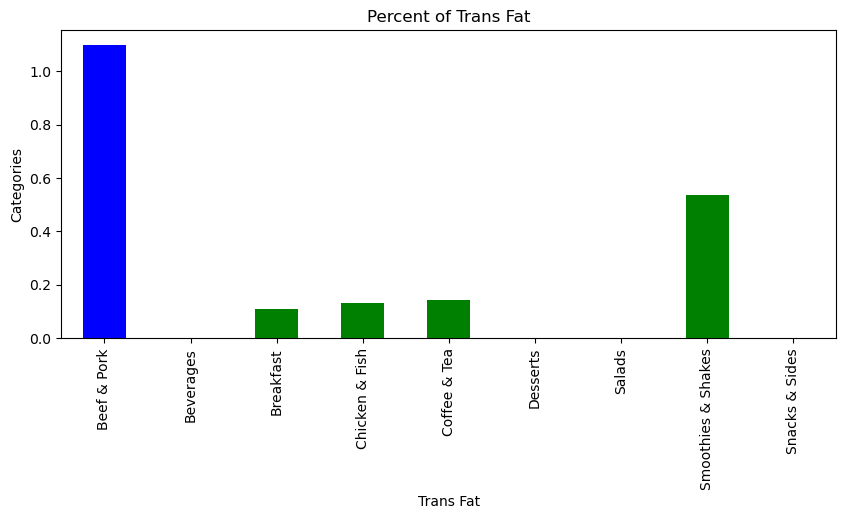

In [6]:
#Bar Graph for Percent of Trans Fat
plt.figure (figsize=(10, 4), dpi=100) #input plot size
menu_category = data.groupby('Category')['Trans Fat'].mean()
menu_category.plot.bar(color = ['blue','green','green','green','green','green','green','green','green'])
plt.title("Percent of Trans Fat")
plt.xlabel("Trans Fat")
plt.ylabel("Categories")
plt.xticks(rotation=90)
plt.show()

In [7]:
data.groupby('Category')['Trans Fat'].mean() # Trans Fat Categories 


Category
Beef & Pork           1.100000
Beverages             0.000000
Breakfast             0.107143
Chicken & Fish        0.129630
Coffee & Tea          0.142105
Desserts              0.000000
Salads                0.000000
Smoothies & Shakes    0.535714
Snacks & Sides        0.000000
Name: Trans Fat, dtype: float64

In [8]:
data['saturated_cholesterol'] = data['Saturated Fat']/data['Cholesterol']*100

In [9]:
saturated_cholesterol = data.groupby('Category')['saturated_cholesterol'].mean().dropna().nlargest(5)

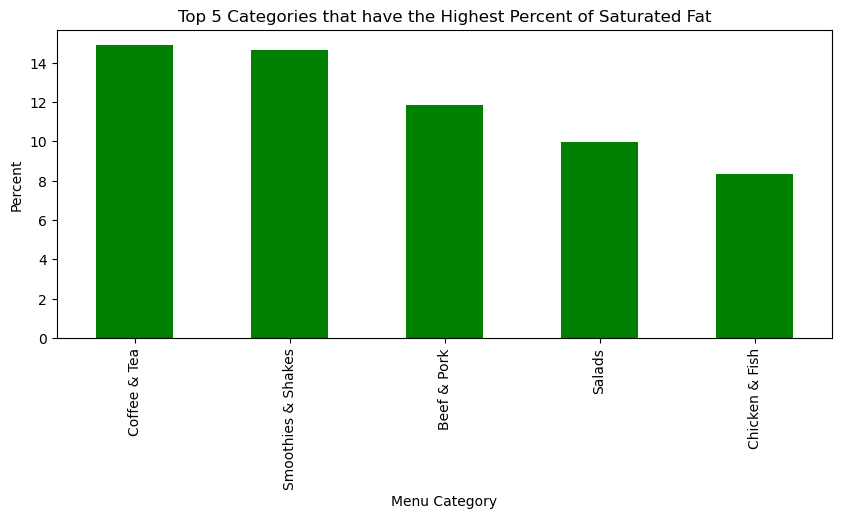

In [10]:
#Bar Graph for Percent of Saturated Fat
plt.figure(figsize=(10, 4), dpi=100)
saturated_cholesterol.sort_values(ascending=False).plot.bar(color = 'green')
plt.title("Top 5 Categories that have the Highest Percent of Saturated Fat")
plt.ylabel("Percent")
plt.xlabel("Menu Category")
plt.xticks(rotation=90)
plt.show();

In [11]:
#Saturated Cholesterol Data
coffee_tea = data[data.Category == 'Coffee & Tea']
coffee_tea.groupby('Item')['saturated_cholesterol'].mean().sort_values(ascending=False)

Item
Frappé Chocolate Chip (Small)     21.538462
Frappé Chocolate Chip (Medium)    21.250000
Frappé Chocolate Chip (Large)     21.052632
Hazelnut Iced Coffee (Small)      20.000000
Hazelnut Latte (Medium)           20.000000
                                    ...    
Iced Tea (Small)                        NaN
Sweet Tea (Child)                       NaN
Sweet Tea (Large)                       NaN
Sweet Tea (Medium)                      NaN
Sweet Tea (Small)                       NaN
Name: saturated_cholesterol, Length: 95, dtype: float64

In [12]:
shakes = data[data.Category == 'Smoothies & Shakes']
shakes.groupby('Item')['saturated_cholesterol'].mean().sort_values()

Item
Blueberry Pomegranate Smoothie (Medium)               0.000000
Blueberry Pomegranate Smoothie (Small)                0.000000
Mango Pineapple Smoothie (Medium)                     0.000000
Mango Pineapple Smoothie (Small)                      0.000000
Strawberry Banana Smoothie (Small)                    0.000000
Strawberry Banana Smoothie (Medium)                   0.000000
Blueberry Pomegranate Smoothie (Large)               10.000000
Mango Pineapple Smoothie (Large)                     10.000000
Strawberry Banana Smoothie (Large)                   10.000000
Chocolate Shake (Medium)                             16.000000
Vanilla Shake (Medium)                               16.000000
Shamrock Shake (Medium)                              16.000000
Vanilla Shake (Large)                                16.666667
Strawberry Shake (Small)                             16.666667
Strawberry Shake (Large)                             16.666667
Shamrock Shake (Large)                            

In [13]:
beef_pork = data[data.Category == 'Beef & Pork']
beef_pork.groupby('Item')['saturated_cholesterol'].mean().sort_values()

Item
Hamburger                                    10.000000
McDouble                                     10.666667
Bacon McDouble                               11.111111
Cheeseburger                                 11.111111
Double Cheeseburger                          11.111111
Daily Double                                 11.250000
Jalapeño Double                              11.250000
Big Mac                                      11.764706
Double Quarter Pounder with Cheese           11.875000
Quarter Pounder with Bacon & Cheese          12.380952
Quarter Pounder with Bacon Habanero Ranch    12.380952
Quarter Pounder with Cheese                  12.631579
Quarter Pounder Deluxe                       12.941176
Bacon Clubhouse Burger                       13.043478
McRib                                        14.285714
Name: saturated_cholesterol, dtype: float64

In [14]:
chicken_fish = data[data.Category == 'Chicken & Fish']
chicken_fish.groupby('Item')['saturated_cholesterol'].mean().sort_values()


Item
Premium Grilled Chicken Classic Sandwich                 3.076923
Premium McWrap Chicken Sweet Chili (Grilled Chicken)     4.615385
Premium Grilled Chicken Ranch BLT Sandwich               5.000000
Southern Style Crispy Chicken Sandwich                   6.666667
Premium Grilled Chicken Club Sandwich                    6.666667
Bacon Clubhouse Grilled Chicken Sandwich                 7.272727
Premium McWrap Chicken & Bacon (Grilled Chicken)         7.368421
Chicken McNuggets (20 piece)                             7.407407
Premium McWrap Chicken & Ranch (Grilled Chicken)         7.500000
Premium McWrap Southwest Chicken (Grilled Chicken)       7.500000
Chicken McNuggets (6 piece)                              7.500000
Chicken McNuggets (40 piece)                             7.547170
Chicken McNuggets (10 piece)                             7.692308
Premium Crispy Chicken Classic Sandwich                  7.777778
Chicken McNuggets (4 piece)                              8.000000
McChi

<h1>The Breakdown</h1>

<b> Vitamin A: </b>An essential nutrient known for its benefits in protecting the eyes, supporting the immune system, and promoting healthy growth. Among various food categories, salads have the highest concentration of Vitamin A, followed by chicken and fish, as well as smoothies and shakes.

<b>Vitamin C: </b> A crucial vitamin that plays a role in boosting immunity and managing high blood pressure. When it comes to McDonald's food offerings, they tend to be richer in Vitamin A compared to Vitamin C. The food categories with the highest levels of Vitamin C include salads, snacks and sides, and beverages.Within the snacks category, apple slices contain the highest amount of Vitamin C. Interestingly, McDonald's french fries also contain notable levels of Vitamin C, as potatoes are a natural source of this nutrient.

In the beverage category, it's worth noting that apple and orange juices are particularly rich in Vitamin C. However, other beverages and drinks like Coke and Sprite are generally low in vitamin content.








In [15]:
data.groupby('Category')['Vitamin A (% Daily Value)'].mean()

Category
Beef & Pork             6.933333
Beverages               0.740741
Breakfast               6.928571
Chicken & Fish         20.444444
Coffee & Tea           10.736842
Desserts                5.142857
Salads                146.666667
Smoothies & Shakes     18.750000
Snacks & Sides          4.846154
Name: Vitamin A (% Daily Value), dtype: float64

In [16]:
data.groupby('Category')['Vitamin C (% Daily Value)'].mean()

Category
Beef & Pork            7.333333
Beverages             23.481481
Breakfast              8.904762
Chicken & Fish        12.629630
Coffee & Tea           0.000000
Desserts               4.142857
Salads                28.333333
Smoothies & Shakes     6.964286
Snacks & Sides        28.153846
Name: Vitamin C (% Daily Value), dtype: float64

In [17]:
beverage = data[data.Category == 'Beverages']
beverage.groupby('Item')['Vitamin C (% Daily Value)'].mean().sort_values()

Item
Diet Dr Pepper (Small)                 0.0
Sprite (Large)                         0.0
Sprite (Child)                         0.0
Fat Free Chocolate Milk Jug            0.0
Dr Pepper (Small)                      0.0
Dr Pepper (Medium)                     0.0
Dr Pepper (Large)                      0.0
Dr Pepper (Child)                      0.0
Sprite (Medium)                        0.0
Diet Dr Pepper (Medium)                0.0
Diet Dr Pepper (Large)                 0.0
Sprite (Small)                         0.0
Diet Coke (Small)                      0.0
Diet Coke (Medium)                     0.0
Diet Coke (Large)                      0.0
Diet Coke (Child)                      0.0
Dasani Water Bottle                    0.0
Coca-Cola Classic (Small)              0.0
Coca-Cola Classic (Medium)             0.0
Coca-Cola Classic (Large)              0.0
Coca-Cola Classic (Child)              0.0
Diet Dr Pepper (Child)                 0.0
1% Low Fat Milk Jug                    4.0
Minute

<h1> Iron and Calcium </h1>

Shakes (fruit shakes, milk shakes etc.), coffee and tea are rich in calcium but low in iron

Menu categories rich in Animal protein (Beef & Pork, Chicken & Fish) are rich in both Iron and Calcium

Mcdonald's beverages are very low in Calcium and Iron.This analysis presents a comprehensive overview of the McDonald's Menu, highlighting the nutritional value of each food category. With this information, you can make informed choices based on your personal preferences or specific nutritional requirements.

McDonald's offers a variety of foods that are abundant in essential vitamins, particularly Vitamin A and C, with salads standing out as a particularly rich source. Additionally, many menu items are low in carbohydrates and contain little to no trans-fat, which is a positive aspect. However, it is important to note that several foods are high in saturated fat. If you are watching your fat intake, it is advisable to select options with low saturated fat content, aiming for less than 10%.

Moreover, this analysis also takes into account essential minerals such as calcium and iron. It was observed that foods on the menu that contain milk or animal protein tend to be particularly rich in calcium, providing a valuable source of this mineral.

In [18]:
iron = data.groupby('Category')['Iron (% Daily Value)'].mean()
calcium = data.groupby('Category')['Calcium (% Daily Value)'].mean()

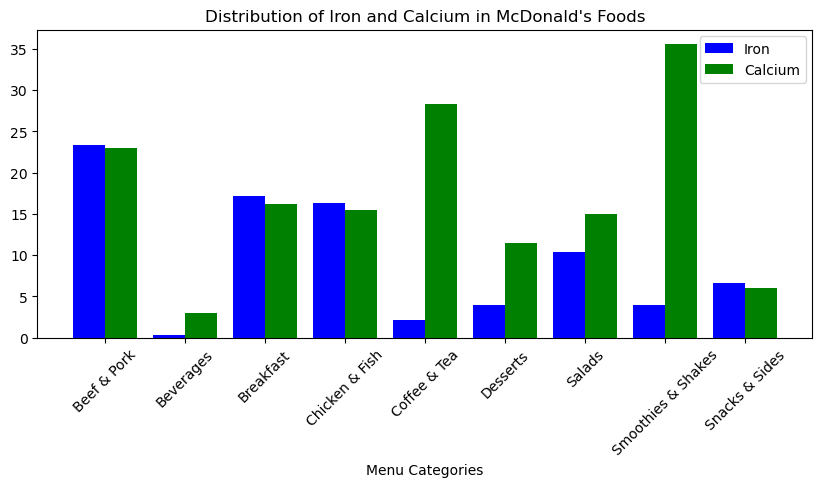

In [19]:
plt.figure(figsize=(10, 4), dpi=100)

category = iron.index
Iron = iron.values
Calcium = calcium.values

X_axis = np.arange(len(category))

plt.bar(X_axis - 0.2, Iron, 0.4, label = 'Iron', color = 'blue')
plt.bar(X_axis + 0.2, Calcium, 0.4, label = 'Calcium', color = 'green')

plt.xticks(X_axis, category)
plt.xlabel("Menu Categories")
plt.title("Distribution of Iron and Calcium in McDonald's Foods")
plt.xticks(rotation=45)
plt.legend()
plt.show()


<h1>Let's Sum Things Up</h1>

This comprehensive analysis delves into the McDonald's Menu, providing detailed nutritional information for each food category. By reviewing this analysis, individuals can make informed choices based on their preferences and dietary requirements.

Many items on McDonald's menu, particularly salads, are notably high in vitamins like Vitamin A and C, while most items are low in carbohydrates and contain little to no trans-fat, which is a positive aspect. However, it's crucial to be mindful of the high saturated fat content in many menu items; those seeking to limit their saturated fat intake should opt for items with less than 10% saturated fat. Additionally, the analysis includes insights into essential minerals such as calcium and iron, revealing that menu items containing milk or animal protein are particularly rich in calcium.